# Citi Bike Avalibility Predictor

Performing EDA and model training and testing

### Import Libraries

In [68]:
import pandas as pd
from zoneinfo import ZoneInfo
from datetime import datetime as dt, timezone, timedelta
import holidays
import seaborn as sns
import json
import meteostat as ms
import numpy as np

### Import station data
Map each station's 'shortname' to their important features

In [2]:
stations_df = pd.read_csv('All_Data/Station_Info/citibike-stations.csv')
id_to_shortname = dict(zip(stations_df['station_id'], stations_df['short_name']))
id_to_lat = dict(zip(stations_df['station_id'], stations_df['lat']))
id_to_lon = dict(zip(stations_df['station_id'], stations_df['lon']))
id_to_name = dict(zip(stations_df['station_id'], stations_df['name']))
shortname_to_name = dict(zip(stations_df['short_name'], stations_df['name']))

In [45]:
stations_df.head()

,capacity,eightd_has_key_dispenser,electric_bike_surcharge_waiver,external_id,has_kiosk,lat,lon,name,region_id,rental_methods,rental_url,short_name,station_id
0,66,True,False,66db5fae-0aca-11e7-82f6-3863bb44ef7c,True,40.764397,-73.973715,Grand Army Plaza & Central Park S,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,6839.1,281
1,33,True,False,66db6da2-0aca-11e7-82f6-3863bb44ef7c,True,40.704633,-74.013617,Broadway & Battery Pl,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,4962.01,304
2,64,False,False,66dbc982-0aca-11e7-82f6-3863bb44ef7c,True,40.755103,-73.974987,E 47 St & Park Ave,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,6584.12,359
3,45,False,False,66dbe441-0aca-11e7-82f6-3863bb44ef7c,True,40.722438,-74.005664,6 Ave & Canal St,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,5500.07,377
4,36,False,False,66dbe601-0aca-11e7-82f6-3863bb44ef7c,True,40.734927,-73.992005,University Pl & E 14 St,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,5905.11,382


# Exploratory Data Analysis


**Load the cleaned dataset:**

- 'valset_dense_few_stations' has all the data collected for just a few bike stations. This detailed data creates better vizualzations
- Unfortuantly I don't have enough RAM to load all the available data for all stations for training
 

In [102]:
df_viz = process_file('All_Data/Cleaned/few_2019_dense.parquet')


Before dropping NA: 1088066 rows
After dropping NA: 1087037 rows


In [103]:
print("Loaded stations : ")

stations_viz = list(df_viz['shortname'].unique())

for station in stations_viz:
    print(shortname_to_name[station], ': ', station)

Loaded stations : 
Park Pl & Church St :  5288.08
Mercer St & Spring St :  5532.01
South St & Whitehall St :  4846.01
Centre St & Worth St :  5279.03
W 13 St & 7 Ave :  6030.04
Broadway & Battery Pl :  4962.01
Clinton St & Grand St :  5303.06
Centre St & Chambers St :  5207.01
E 7 St & Avenue A :  5626.07


### Visualizations of Typical Daily Cycles

**Mercer St & Spring St** is located near NYU and SOHO in the central city.
- Below is graphed 4/7 to 4/13 a full week from Sunday to Saturday
- The upward and downward cyclic trend during the weekdays in very clear, however there is significant variation between how far cycles rise and dip limiting the accuracy of a potential model
- Weekends show high station capacities but very pretty unpredicable variation

Mercer St & Spring St :


<Axes: xlabel='timestamp', ylabel='percentage_available'>

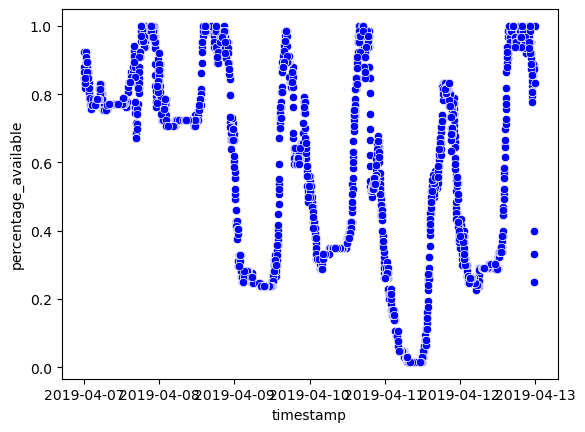

In [95]:
SHORTNAME = '5532.01'

timeframe_graphed = (df_viz['timestamp'] >= dt(2019,4,7, tzinfo = timezone.utc)) & (df_viz['timestamp'] < dt(2019,4, 13, tzinfo = timezone.utc))
print(shortname_to_name[SHORTNAME], ':')

sns.scatterplot(data= df_viz[(df_viz['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='percentage_available', color = 'blue')

**Single Cycle (Weekday)**
- Not sure about the uptick at the afternoon, but it seems to happen every day, maybe some event at the station specifically?

Mercer St & Spring St :


<Axes: xlabel='timestamp', ylabel='percentage_available'>

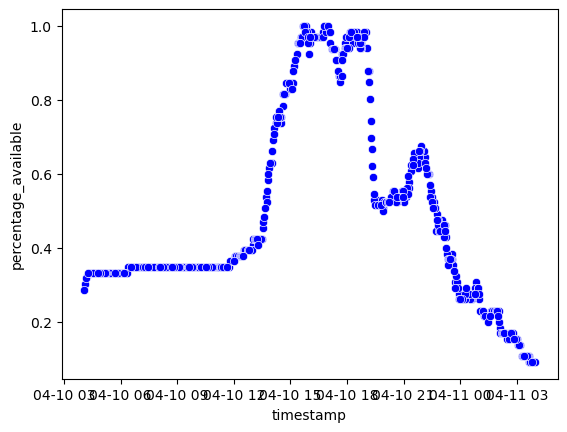

In [ ]:
SHORTNAME = '5532.01'

timeframe_graphed = (df_viz['timestamp'] >= dt(2019,4,10, tzinfo = ZoneInfo("America/New_York"))) & (df_viz['timestamp'] < dt(2019,4, 11, tzinfo = ZoneInfo("America/New_York")))
print(shortname_to_name[SHORTNAME], ':')

sns.scatterplot(data= df_viz[(df_viz['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='percentage_available', color = 'blue')

**E 7 St & Avenue A** is located in East Village in a residential center.
- The same week is graphed 4/7 to 4/13
- The similar predictable cyclic trend is visible on the weekdays with weekends have more variation.
- Alignment of cyclic is the opposite to inner city stations from commuter behaviour
- Stations is severe in lacking bikes or docks when needed


E 7 St & Avenue A :


<Axes: xlabel='timestamp', ylabel='percentage_available'>

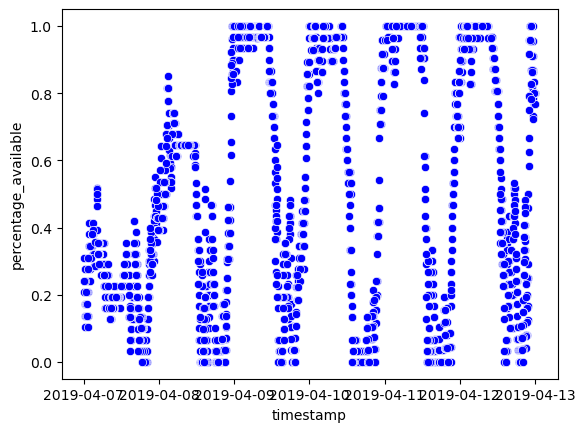

In [ ]:
SHORTNAME = '5626.07'

timeframe_graphed = (df_viz['timestamp'] >= dt(2019,4,7, tzinfo = timezone.utc)) & (df_viz['timestamp'] < dt(2019,4, 13, tzinfo = timezone.utc))
print(shortname_to_name[SHORTNAME], ':')

sns.scatterplot(data= df_viz[(df_viz['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='percentage_available', color = 'blue')

**Daily Cycle** 
- opposite for a commuter bike station as expected

E 7 St & Avenue A :


<Axes: xlabel='timestamp', ylabel='percentage_available'>

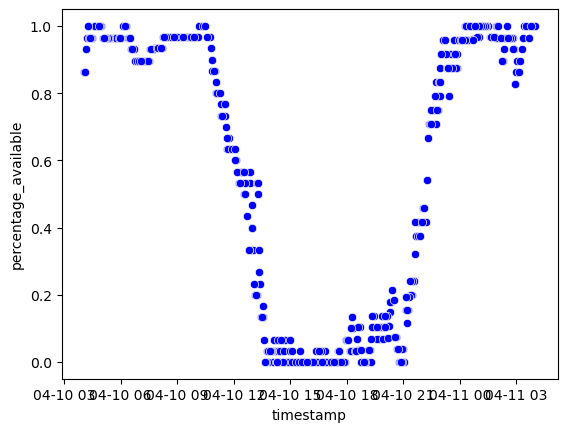

In [ ]:
SHORTNAME = '5626.07'

timeframe_graphed = (df_viz['timestamp'] >= dt(2019,4,10, tzinfo = ZoneInfo("America/New_York"))) & (df_viz['timestamp'] < dt(2019,4, 11, tzinfo = ZoneInfo("America/New_York")))
print(shortname_to_name[SHORTNAME], ':')

sns.scatterplot(data= df_viz[(df_viz['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='percentage_available', color = 'blue')

### Some more Capacity Data
-  Percentage of time each stations had no docs or no bikes

In [103]:
df_viz['station_name'] = df_viz['shortname'].map(shortname_to_name)

nobikes_perc = df_viz.groupby('station_name')['percentage_available'].apply(lambda x: round((x == 0).mean() * 100, 2))
noracks_perc = df_viz.groupby('station_name')['percentage_available'].apply(lambda x: round((x == 1).mean() * 100, 2))

nobikes_perc = nobikes_perc.sort_values()
noracks_perc = noracks_perc.sort_values()

print("--------------")
print("Percentage of time with no bike available: ")
print("--------------")
print(nobikes_perc)
print("--------------")

print("Percentage of time with no docks available: ")
print("--------------")
print(noracks_perc)
print("--------------")

/tmp/ipykernel_11691/84476664.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  nobikes_perc = df_viz.groupby('station_name')['percentage_available'].apply(lambda x: round((x == 0).mean() * 100, 2))
/tmp/ipykernel_11691/84476664.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  noracks_perc = df_viz.groupby('station_name')['percentage_available'].apply(lambda x: round((x == 1).mean() * 100, 2))


--------------
Percentage of time with no bike available: 
--------------
station_name
South St & Whitehall St    4.53
Canal St & Rutgers St      4.54
Broadway & Battery Pl      4.70
W 13 St & 7 Ave            4.94
Clinton St & Grand St      6.71
Centre St & Chambers St    7.03
Mercer St & Spring St      7.05
E 7 St & Avenue A          7.46
Centre St & Worth St       7.95
Park Pl & Church St        8.98
Name: percentage_available, dtype: float64
--------------
Percentage of time with no docks available: 
--------------
station_name
Broadway & Battery Pl       1.05
Centre St & Worth St        2.71
Centre St & Chambers St     2.89
W 13 St & 7 Ave             2.96
South St & Whitehall St     4.21
Canal St & Rutgers St       4.34
Park Pl & Church St         4.70
E 7 St & Avenue A           6.13
Mercer St & Spring St       6.55
Clinton St & Grand St      11.38
Name: percentage_available, dtype: float64
--------------


## Data Pipeline

### Final Pipeline

Implemented Basic Time and Location Features

In [108]:
df_columns = ['shortname', 'Month', 'Day', 'Hour', 
                   'IsWeekend', 'IsHoliday', 'IsNonWorkingDay', 'lat', 'lon', 'IsRushHour','timestamp','minute'
                   ,'temp','prcp','snwd','wspd','time_since_rain','time_since_dry'
                   ]



def add_features(df):
    
    df = df.drop('station_status_last_reported', axis=1)

    df['Month'] = df['timestamp'].dt.month
    df['Day'] = df['timestamp'].dt.dayofweek
    df['Hour'] = df['timestamp'].dt.hour
    df['IsWeekend'] = df['Day'].isin([5,6]).astype(int)
    df['lat'] = df['station_id'].map(id_to_lat)
    df['lon'] = df['station_id'].map(id_to_lon)
    df['minute'] = df['timestamp'].dt.minute
    df['percentage_available'] = df['num_bikes_available'] / (df['num_bikes_available'] + df['num_docks_available'])
    df['IsRushHour'] = ((df['Hour'].isin([7,8,9,16,17,18])) & (df['IsWeekend'] == 0)).astype(int)
    df['shortname'] = df['station_id'].map(id_to_shortname)


    ny_holidays = holidays.US(state='NY')
    holiday_date_list = list(ny_holidays.keys())

    df['IsHoliday'] = df['timestamp'].dt.date.isin(holiday_date_list).astype(int)
    df['IsNonWorkingDay'] = ((df['IsWeekend'] == 1) | (df['IsHoliday'] == 1)).astype(int)
    df = add_weather(df)

    return df

def process_file(csv_file):
    df = pd.read_parquet(csv_file)
    df['timestamp'] = df['station_status_last_reported']
    
    df = add_features(df)

    print(f"Before dropping NA: {df.shape[0]} rows")
    # I actually have no idea about this isna() vs isnan bug
    df.loc[np.isnan(df['percentage_available']), 'percentage_available'] = pd.NA
    df = df[df_columns + ['percentage_available']].dropna()
    print(f"After dropping NA: {df.shape[0]} rows")
    df['shortname'] = df['shortname'].astype('category')

    

    return df
    

### Some Feature Experimentation

- **Tested a station volitatity feature**: The idea was for the trees to spend less splits finding stations that had predicting patterns. 
  The model ended up performing worse though (mostly due to poor implemention of the features), but just running more iterations
  to construct a deeper tree is sufficient

- **Potential Weather feature**: I considered adding a weather feature, relying on weather forecast (will implement later)

- **Potential Lag Features**: Maybe later as well but not sure how significant this will be


In [4]:
def add_vol(df):

    hourly_variances = df.groupby(['station_id', 'Hour'])['percentage_available'].var()
    station_volatility = hourly_variances.groupby(level=0).mean()
    df['Volatility'] = df['station_id'].map(station_volatility)
    return df;

In [61]:
df_weather = pd.read_parquet('All_Data/Weather_Data/weather_data.parquet')

In [71]:

def add_weather(df):
    df['hour_key'] = df['timestamp'].dt.floor('h')

    # time since rain feature??
    last_rain = df_weather.iloc[0]['time']
    time_since_rain = []
    for i in range(len(df_weather)):
        curr = df_weather.iloc[i]
        if curr['prcp'] > 0:
            last_rain = curr['time']
        time_since_rain.append((curr['time'] - last_rain).total_seconds())

    # time since dry feature??
    last_dry = df_weather.iloc[0]['time']
    time_since_dry = []
    for i in range(len(df_weather)):
        curr = df_weather.iloc[i]
        if not (curr['prcp'] > 0 or curr['snwd'] > 0):
            last_dry = curr['time']
        time_since_dry.append((curr['time'] - last_dry).total_seconds())



    df_weather['time_since_rain'] = time_since_rain
    df_weather['time_since_dry'] = time_since_dry
    

    df_final = pd.merge(
    df, 
    df_weather, 
    left_on='hour_key', 
    right_on='time', 
    how='left'       
    )

    return df_final

## XG Boost Model Training + Testing

- XGBoost chosen for non-linearity and incapasulating complex feature relationships
- Used CatBoost for categorical importance of distinguishing between individual station trends

### Import Libraries

In [6]:
import numpy as np
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from catboost import CatBoostRegressor


### Create train and validation sets

- Used a simple validation setup: years **2017 to 2018** for training and year **2019** for validation (omitted 2020, 2021 for COVID and 2016 for the system being in an earlier stage)
- Trained the model out a randomly sampled subset of the total collected data due to RAM limitations

In [109]:
df = process_file('All_Data/Cleaned/large_2017-2018_500,000per.parquet')
feature_columns = ['shortname', 'Month', 'Day', 'Hour', 
                   'IsWeekend', 'IsHoliday', 'IsNonWorkingDay', 'lat', 'lon', 'IsRushHour','minute'
                   ,'temp','prcp','snwd','wspd','time_since_rain','time_since_dry'
                   ]


X_train = df[feature_columns]
y_train = df['percentage_available']

Before dropping NA: 1321222 rows
After dropping NA: 1318943 rows


In [54]:
col = 'percentage_available' # Put the specific column name here

# Get the boolean masks for both
numpy_mask = np.isnan(df[col])
pandas_mask = pd.isna(df[col])

# Find where numpy says "YES it's missing" BUT pandas says "NO it's not"
rogue_values = df[col][numpy_mask & ~pandas_mask]

print(f"NumPy found {numpy_mask.sum()} missing values.")
print(f"Pandas found {pandas_mask.sum()} missing values.")
print("-" * 30)
print("The exact values NumPy caught but Pandas missed:")
print(rogue_values.unique())
print("Their exact Python data types:")
print(rogue_values.apply(type).unique())

NumPy found 502 missing values.
Pandas found 0 missing values.
------------------------------
The exact values NumPy caught but Pandas missed:
<FloatingArray>
[nan]
Length: 1, dtype: Float64
Their exact Python data types:
[<class 'float'>]


In [110]:
val_dataset = process_file('All_Data/Cleaned/large_2019_500,000per.parquet')
X_val = val_dataset[feature_columns]
y_val = val_dataset['percentage_available']

Before dropping NA: 666945 rows
After dropping NA: 666377 rows


In [31]:
def evaluate_model(predicted, actual):
    train_mae = mean_absolute_error(predicted, actual)
    train_rmse = np.sqrt(mean_squared_error(predicted, actual))
    train_r2 = r2_score(predicted, actual)

    print(f"  MAE:  {train_mae:.4f}")
    print(f"  RMSE: {train_rmse:.4f}")
    print(f"  R²:   {train_r2:.4f}")

## Model Training

In [111]:
# Train baseline XGBoost model
print("Training baseline XGBoost model...")

# Initialize XGBoost regressor with default parameters
baseline_model = CatBoostRegressor(
    iterations=2000,
    learning_rate= 0.05,
    depth=4,
    loss_function='RMSE',
    eval_metric='RMSE',
    random_seed=42,
    verbose=100
)

baseline_model.fit(X_train, y_train, cat_features=['shortname', 'Month','Day'], eval_set=(X_val, y_val))

y_train_pred = baseline_model.predict(X_train)
y_val_pred = baseline_model.predict(X_val)

train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2 = r2_score(y_train, y_train_pred)

val_mae = mean_absolute_error(y_val, y_val_pred)
val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
val_r2 = r2_score(y_val, y_val_pred)


print("\n=== Baseline Model Performance ===")
print(f"\nTraining Set:")
print(f"  MAE:  {train_mae:.4f}")
print(f"  RMSE: {train_rmse:.4f}")
print(f"  R²:   {train_r2:.4f}")

print(f"\nValidation Set:")
print(f"  MAE:  {val_mae:.4f}")
print(f"  RMSE: {val_rmse:.4f}")
print(f"  R²:   {val_r2:.4f}")



Training baseline XGBoost model...
0:	learn: 0.3353032	test: 0.3344836	best: 0.3344836 (0)	total: 574ms	remaining: 19m 6s
100:	learn: 0.2564868	test: 0.3063962	best: 0.3061485 (59)	total: 21.2s	remaining: 6m 37s
200:	learn: 0.2488938	test: 0.3052285	best: 0.3051983 (195)	total: 45.1s	remaining: 6m 43s
300:	learn: 0.2442311	test: 0.3033704	best: 0.3033704 (300)	total: 1m 15s	remaining: 7m 3s
400:	learn: 0.2407134	test: 0.3028667	best: 0.3027717 (387)	total: 1m 46s	remaining: 7m 6s
500:	learn: 0.2381552	test: 0.3020840	best: 0.3020840 (500)	total: 2m 18s	remaining: 6m 53s
600:	learn: 0.2361985	test: 0.3020870	best: 0.3019869 (529)	total: 2m 49s	remaining: 6m 35s
700:	learn: 0.2344064	test: 0.3018039	best: 0.3018005 (693)	total: 3m 21s	remaining: 6m 13s
800:	learn: 0.2330659	test: 0.3016865	best: 0.3016252 (795)	total: 3m 53s	remaining: 5m 49s
900:	learn: 0.2317868	test: 0.3015852	best: 0.3015289 (880)	total: 4m 26s	remaining: 5m 25s
1000:	learn: 0.2305487	test: 0.3013532	best: 0.3013014 

### Confirmation Validation Test with full data for a few stations
- Just a sanity check

In [105]:


X_smallval = df_viz[feature_columns]
y_smallval = df_viz['percentage_available']

y_smallval_pred = baseline_model.predict(X_smallval)


val_mae = mean_absolute_error(y_smallval, y_smallval_pred)
val_rmse = np.sqrt(mean_squared_error(y_smallval, y_smallval_pred))
val_r2 = r2_score(y_smallval, y_smallval_pred)

print(f"\nSmall Validation Set:")
print(f"  MAE:  {val_mae:.4f}")
print(f"  RMSE: {val_rmse:.4f}")
print(f"  R²:   {val_r2:.4f}")


Small Validation Set:
  MAE:  0.2478
  RMSE: 0.3070
  R²:   0.1078


In [42]:
baseline_model.save_model('Weather_Model.cbm')



### Model Performance Logs
- Code used to track the performance of different test models, stored logs in csv

In [41]:

model_logs = pd.read_csv('model_logs.csv')
model_logs.loc[len(model_logs)] = pd.Series({
    'model_name': '3500 iter, 9 tree depth??',
    'train_mae': val_mae,
    'train_rmse': val_rmse,
    'R^2': val_r2,
    'hyperparams': '3500 iterations, 0.7 learning, 9 depth',
    'features_used': 'weather + time since rain + time since dry',
    'notes': 'tree depth might still need to be higher, satified with this for now since training takes so long'
})

model_logs.to_csv('model_logs.csv', index=False)

In [39]:
model_logs = pd.read_csv('model_logs.csv')
pd.set_option('display.max_colwidth', None)
model_logs

,model_name,train_mae,train_rmse,R^2,hyperparams,features_used,notes
0,Baseline CatBoost,0.143460,0.187209,0.624322,default,"NO lag features, baseline","Default parameters, seems kinda weak, ran on medium sized dataset with just sparse data from the first 2 csvs"
1,Cat Boost with first before time stamp lag,0.019427,0.044316,0.978949,default,Only lag from previous measurement and time since last measurement,"Pretty good but I feel like the predictive power is limited since the lags are so close, will have to figure out better lag design"
2,Standard with more data and from 2017 and 2018,0.163594,0.210014,0.515280,"default, will change to 500 iteration since conversion seems to be at around 200",Standard,uhhh i feel like more data had a very marginal improvement
3,Standard with more data and from 2017 and 2018,0.215938,0.277457,0.243575,default,Standard,oops will start logging test results from now on
4,"Standard using only stations in Manhatten under 14th st. Used 2017 to 2018 data with 100,000 cols per csv, used 10,000 per csv for cross val",0.202173,0.256919,0.419616,default,"Standard, added volitatity",lowkey using used stations make big difference
5,"same as previous but I took out volitatiy, turned out to be bad i guess",0.200971,0.255792,0.424698,default,Standard,lowkey using used stations make big difference
6,added minute feature,0.201037,0.255623,0.425459,default,Standard + minute,literally no difference i guess will keep in the model
7,changed max iterations to 1000,0.197427,0.253156,0.436494,default,Standard,"lowkey max iterations makes a gud difference, model is still underfitting and could be better with more"
8,"used dataset with 500,000 rows by per csv",0.173122,0.217899,0.582525,default,Standard,holy shit more data actually matters so much
9,"upgraded to 1,500 iterations",0.169426,0.214200,0.596577,default,Standard,"still underfit but gains were minial, 10 minutes to train"


## Prediction Visualization

- Predict on the same 2 stations: **Mercer & Spring St** and **7th St & Avenue A**
- **RED**: Predicted Values
- **BLUE**: Actual Values

- After more throurough testing, the model doesn't seem like to commit to extreme values for 0 or 1. This is probrably just due to the nature of decision trees, but
  it's unfortunate since those are the 2 most common capacities. This is especially problematic for current 2026 predictions where increase ridership has increased how
  common these extremes occur. Not sure how to address this

Mercer St & Spring St :


<Axes: xlabel='timestamp', ylabel='percentage_available'>

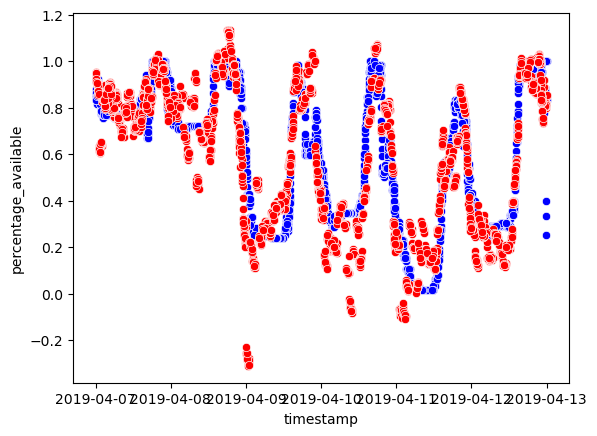

In [45]:

val_dataset['predictions'] = y_smallval_pred

SHORTNAME = '5532.01'

timeframe_graphed = (val_dataset['timestamp'] >= dt(2019,4,7, tzinfo = timezone.utc)) & (val_dataset['timestamp'] < dt(2019,4,13, tzinfo = timezone.utc))

print(shortname_to_name[SHORTNAME], ':')


sns.scatterplot(data= val_dataset[(val_dataset['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='percentage_available', color = 'blue')
sns.scatterplot(data= val_dataset[(val_dataset['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='predictions', color = 'red')



Mercer St & Spring St :


<Axes: xlabel='timestamp', ylabel='percentage_available'>

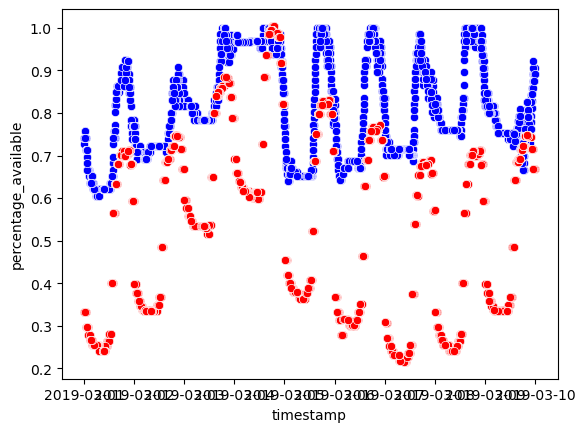

In [100]:

df_viz['predictions'] = y_smallval_pred

SHORTNAME = '5532.01'

timeframe_graphed = (df_viz['timestamp'] >= dt(2019,3,1, tzinfo = timezone.utc)) & (df_viz['timestamp'] < dt(2019,3,10, tzinfo = timezone.utc))

print(shortname_to_name[SHORTNAME], ':')


sns.scatterplot(data= df_viz[(df_viz['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='percentage_available', color = 'blue')
sns.scatterplot(data= df_viz[(df_viz['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='predictions', color = 'red')



E 7 St & Avenue A :


<Axes: xlabel='timestamp', ylabel='percentage_available'>

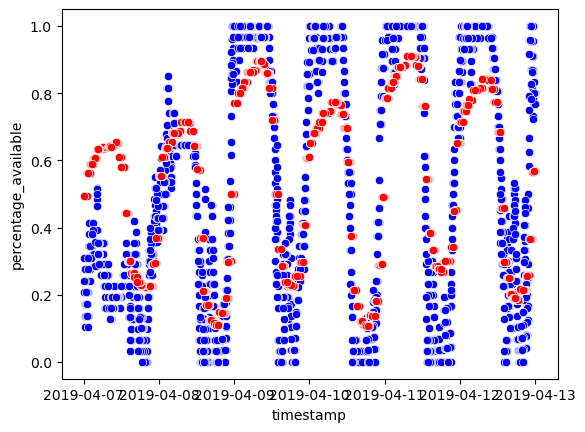

In [106]:

df_viz['predictions'] = y_smallval_pred

SHORTNAME = '5626.07'

timeframe_graphed = (df_viz['timestamp'] >= dt(2019,4,7, tzinfo = timezone.utc)) & (df_viz['timestamp'] < dt(2019,4,13, tzinfo = timezone.utc))

print(shortname_to_name[SHORTNAME], ':')


sns.scatterplot(data= df_viz[(df_viz['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='percentage_available', color = 'blue')
sns.scatterplot(data= df_viz[(df_viz['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='predictions', color = 'red')



E 7 St & Avenue A :


<Axes: xlabel='timestamp', ylabel='percentage_available'>

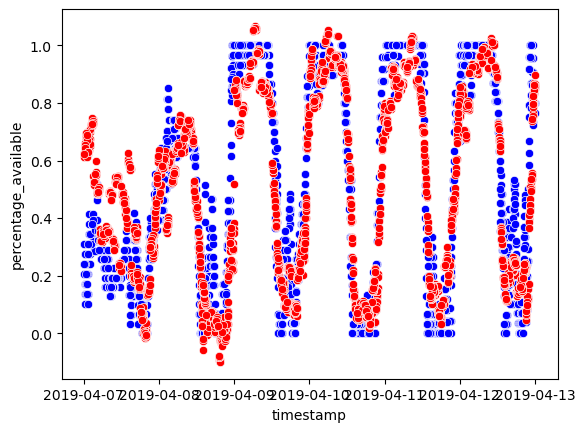

In [46]:
SHORTNAME = '5626.07'

timeframe_graphed = (val_dataset['timestamp'] >= dt(2019,4,7, tzinfo = timezone.utc)) & (val_dataset['timestamp'] < dt(2019,4,13, tzinfo = timezone.utc))

print(shortname_to_name[SHORTNAME], ':')


sns.scatterplot(data= val_dataset[(val_dataset['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='percentage_available', color = 'blue')
sns.scatterplot(data= val_dataset[(val_dataset['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='predictions', color = 'red')


### Quick Baseline Comparison Test

This below model just predicts the 2019 based on the capacities of the same date in 2018.
I tested this model out of curiosity to see how effective my XG Boost, it serves as another baseline to compare to.

The simple "last year" model performed terribly, much worse than I would have thought

In [36]:
df_2018 = df[(df['timestamp'] >= dt(2018,1,1, tzinfo = timezone.utc)) & (df['timestamp'] < dt(2018,12,31, tzinfo = timezone.utc))]
df_2018 = df_2018.sort_values('timestamp')
df_2019 = val_dataset
df_2019 = df_2019.sort_values('timestamp')
df_2019['last_year_time'] = df_2019['timestamp'] - timedelta(days = 365)

df_lag = pd.merge_asof(
    df_2019,
    df_2018[["shortname","timestamp", "percentage_available"]],
    left_on="last_year_time",
    right_on="timestamp",
    direction="backward",
    by = 'shortname',
    suffixes=("", "_lag_1h")
)

df_lag = df_lag.dropna(subset=["percentage_available_lag_1h"])





In [38]:
print("Evaluating simple year back model:")
evaluate_model(df_lag['percentage_available'], df_lag['percentage_available_lag_1h'])

Evaluating simple year back model:
  MAE:  0.3467
  RMSE: 0.4380
  R²:   -0.7736


## Construct Final Model

- Train on combined 2017 - 2019 data